# 05 — Advanced Models
**IDX Exchange Data Science Internship — Predicting California Home Close Prices**

Author: Saanvi Prasad

This notebook covers **Week 7**:
- Try **Gradient Boosting** (I use **LightGBM**)
- Do light **hyperparameter tuning**: tree depth, learning rate, and number of trees (`n_estimators`)
- **Deliverable:** this notebook with test metrics

I use the **Week 6 feature set** (including bed/bath ratio, age, and the school district price level), because it gave the best results last week.

## Setup
LightGBM is a new library. The next cell installs it into the same Python that Jupyter uses. Run it **once**; after that you can skip it. (If it still says *No module named 'lightgbm'*, restart the kernel: **Kernel → Restart**.)

In [5]:
%pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\saanv\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [6]:
import os
import time
import warnings
warnings.filterwarnings("ignore")      # hide version warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

# >>> CHANGE THIS to the folder where your CSV files are (same as before) <<<
path = r"C:\Users\saanv\Desktop\idxexchange"

## 1. Load the data
Same train/test files as Weeks 4–6:
- **Train** = March 2025 – March 2026 (X = 13 months)
- **Test** = April 2026

In [7]:
train = pd.read_csv(os.path.join(path, "train_data.csv"))
test = pd.read_csv(os.path.join(path, "test_data.csv"))

print("Training rows:", len(train), "| months:", train["Month"].min(), "to", train["Month"].max())
print("Test rows:    ", len(test), "| month:", test["Month"].unique()[0])

Training rows: 140798 | months: 2025-03 to 2026-03
Test rows:     12465 | month: 2026-04


## 2. Add the Week 6 features
Same steps as Week 6:
1. **`BedBathRatio`** and **`AgeAtSale`**
2. Match every home to its **school district** (spatial join with the `DistrictAreas2425.shp` map)
3. **`DistrictPriceLevel`**: each district's typical log price per sq ft, from **training homes only**, blended toward the overall median for small districts

I put step 3 in a function, `add_district_level(train_part, other_part)`, because in the tuning step (section 5) the "training homes" are only March 2025 – February 2026. The district level must then be calculated from those months only, so nothing from the validation month leaks in.

In [8]:
# 1. Bed/bath ratio and age
for d in [train, test]:
    d["BedBathRatio"] = d["BedroomsTotal"] / d["BathroomsTotalInteger"]
    d["AgeAtSale"] = d["Month"].str[:4].astype(int) - d["YearBuilt"]
    d.loc[d["AgeAtSale"] < 0, "AgeAtSale"] = 0

# 2. School districts (High school districts last, so overlapping homes keep the more local district)
districts = gpd.read_file(os.path.join(path, "DistrictAreas2425.zip"))
districts["order"] = (districts["DistrictTy"] == "High").astype(int)
districts = districts.sort_values("order")

def add_district(df):
    points = gpd.GeoDataFrame(df[["Longitude", "Latitude"]].copy(),
                              geometry=gpd.points_from_xy(df["Longitude"], df["Latitude"]),
                              crs="EPSG:4326").to_crs(districts.crs)
    joined = gpd.sjoin(points, districts[["DistrictNa", "order", "geometry"]], how="left", predicate="within")
    joined = joined.sort_values("order").groupby(level=0).first()
    df = df.copy()
    df["District"] = joined["DistrictNa"].reindex(df.index)
    return df

train = add_district(train)
test = add_district(test)
print("Homes matched to a district: train", round(train["District"].notna().mean() * 100, 2), "% | test",
      round(test["District"].notna().mean() * 100, 2), "%")


# 3. District price level, learned from train_part only
def add_district_level(train_part, other_part, k=20):
    train_part = train_part.copy()
    other_part = other_part.copy()
    log_ppsf = np.log(train_part["ClosePrice"] / train_part["LivingArea"])
    overall_median = log_ppsf.median()
    stats = log_ppsf.groupby(train_part["District"]).agg(["median", "count"])
    level = (stats["count"] * stats["median"] + k * overall_median) / (stats["count"] + k)
    for d in [train_part, other_part]:
        d["DistrictPriceLevel"] = d["District"].map(level).fillna(overall_median)
    return train_part, other_part

Homes matched to a district: train 99.86 % | test 99.33 %


## 3. Prepare the data (same `prepare()` as Weeks 5–6)

In [9]:
number_cols = ["Latitude", "Longitude", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet",
               "YearBuilt", "GarageSpaces", "Stories"]
flag_cols = ["Latitude", "LotSizeSquareFeet", "YearBuilt", "GarageSpaces", "Stories"]
yes_no_cols = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]
new_cols = ["AgeAtSale", "BedBathRatio", "DistrictPriceLevel"]      # Week 6 features


def prepare(train, test, extra_cols=[]):
    """extra_cols = any new number columns to add (used in Week 6)."""
    train = train.copy()
    test = test.copy()
    num_cols = number_cols + extra_cols

    # 1. Missing values
    for col in flag_cols:                          # flag first (before filling)
        train[col + "_missing"] = train[col].isna().astype(int)
        test[col + "_missing"] = test[col].isna().astype(int)
    for col in num_cols:                           # fill with TRAINING median
        median = train[col].median()
        train[col] = train[col].fillna(median)
        test[col] = test[col].fillna(median)
    for col in yes_no_cols:
        train[col] = train[col].fillna(0)
        test[col] = test[col].fillna(0)
    train["City"] = train["City"].fillna("Unknown")
    test["City"] = test["City"].fillna("Unknown")

    # 2. Log of skewed columns
    for d in [train, test]:
        d["LivingArea"] = np.log(d["LivingArea"])
        d["LotSizeSquareFeet"] = np.log(d["LotSizeSquareFeet"])

    # 3. Encoding: keep cities with 100+ training sales, the rest become "Other"
    city_counts = train["City"].value_counts()
    big_cities = city_counts[city_counts >= 100].index
    train["City"] = train["City"].where(train["City"].isin(big_cities), "Other")
    test["City"] = test["City"].where(test["City"].isin(big_cities), "Other")

    feature_cols = num_cols + [c + "_missing" for c in flag_cols] + yes_no_cols + ["CountyOrParish", "City"]
    X_train = pd.get_dummies(train[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = pd.get_dummies(test[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)   # same columns as train

    # 4. Normalize number columns with TRAINING mean and std
    for col in num_cols:
        mean = X_train[col].mean()
        std = X_train[col].std()
        X_train[col] = (X_train[col] - mean) / std
        X_test[col] = (X_test[col] - mean) / std

    y_train = np.log(train["ClosePrice"])
    y_test = np.log(test["ClosePrice"])
    return X_train, X_test, y_train, y_test


train_lvl, test_lvl = add_district_level(train, test)
X_train, X_test, y_train, y_test = prepare(train_lvl, test_lvl, extra_cols=new_cols)
actual_price = np.exp(y_test)
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

X_train: (140798, 403)
X_test:  (12465, 403)


## 4. What is Gradient Boosting?
A **Random Forest** builds 100 trees *independently* and averages them.

**Gradient Boosting** builds trees **one after another**, and each new tree tries to **fix the mistakes** of all the trees before it:
1. Tree 1 makes a rough prediction.
2. Tree 2 looks at where tree 1 was wrong (the errors) and learns to correct them.
3. Tree 3 corrects what's still wrong… and so on, for hundreds of small trees.

**LightGBM** is a fast library for gradient boosting. The three settings I tune:

| Setting | What it does | Too small | Too big |
|---|---|---|---|
| `max_depth` | how many yes/no questions each tree can ask | trees too simple | trees overfit |
| `learning_rate` | how much each new tree is allowed to correct | needs many more trees | jumps around, overfits |
| `n_estimators` | how many trees in total | underfits | overfits (and slow) |

## 5. Light hyperparameter tuning (on March 2026, not the test month)
Same idea as choosing X in Week 3 and the tree depth in Week 5: I **don't** tune on April. I train on **March 2025 – February 2026** and score on **March 2026** (validation).

To tune `n_estimators` without training a separate model for every number, I train each model with up to **5,000 trees** and record the validation error **after every tree**. Then I pick the number of trees where the validation error was lowest.

I try every combination of:
- `max_depth`: **4, 6, 8**
- `learning_rate`: **0.05, 0.1**



In [10]:
fit_part = train[train["Month"] < "2026-03"]
val_part = train[train["Month"] == "2026-03"]
fit_lvl, val_lvl = add_district_level(fit_part, val_part)          # district level from fit months only
X_fit, X_val, y_fit, y_val = prepare(fit_lvl, val_lvl, extra_cols=new_cols)

tuning = []
for depth in [4, 6, 8]:
    for lr in [0.05, 0.1]:
        start = time.time()
        model = lgb.LGBMRegressor(n_estimators=5000, learning_rate=lr, max_depth=depth,
                                  num_leaves=2 ** depth - 1, min_child_samples=20,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  random_state=42, verbose=-1)
        model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], eval_metric="l2")
        val_error = model.evals_result_["valid_0"]["l2"]           # error after each tree
        best_trees = int(np.argmin(val_error)) + 1
        pred_val = model.predict(X_val, num_iteration=best_trees)
        tuning.append({
            "max_depth": depth, "learning_rate": lr, "best n_estimators": best_trees,
            "validation R2": r2_score(np.exp(y_val), np.exp(pred_val)),
            "validation R2 (log)": r2_score(y_val, pred_val),
            "seconds": round(time.time() - start, 1),
        })
        print(f"depth={depth}, learning_rate={lr}: best at {best_trees} trees, "
              f"validation R² = {tuning[-1]['validation R2']:.4f}")

tuning = pd.DataFrame(tuning).sort_values("validation R2", ascending=False)
tuning

depth=4, learning_rate=0.05: best at 5000 trees, validation R² = 0.8659
depth=4, learning_rate=0.1: best at 4985 trees, validation R² = 0.8511
depth=6, learning_rate=0.05: best at 5000 trees, validation R² = 0.8662
depth=6, learning_rate=0.1: best at 4612 trees, validation R² = 0.8485
depth=8, learning_rate=0.05: best at 4537 trees, validation R² = 0.8540
depth=8, learning_rate=0.1: best at 2438 trees, validation R² = 0.8635


,max_depth,learning_rate,best n_estimators,validation R2,validation R2 (log),seconds
2,6,0.0500,5000,0.8662,0.9389,20.6000
0,4,0.0500,5000,0.8659,0.9344,44.1000
5,8,0.1000,2438,0.8635,0.9379,23.5000
4,8,0.0500,4537,0.8540,0.9394,25.7000
1,4,0.1000,4985,0.8511,0.9361,14.8000
3,6,0.1000,4612,0.8485,0.9383,70.8000


Best settings: max_depth=6, learning_rate=0.05, n_estimators=5000


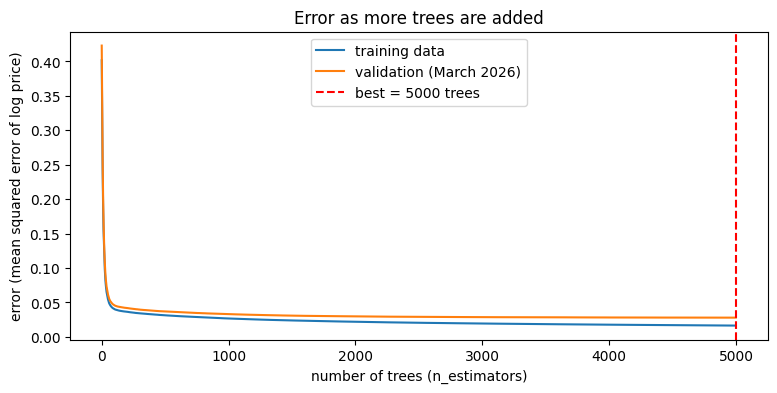

In [11]:
best = tuning.iloc[0]
best_depth = int(best["max_depth"])
best_lr = float(best["learning_rate"])
best_trees = int(best["best n_estimators"])
print(f"Best settings: max_depth={best_depth}, learning_rate={best_lr}, n_estimators={best_trees}")

# Show how the validation error changes as trees are added, for the best settings
curve_model = lgb.LGBMRegressor(n_estimators=5000, learning_rate=best_lr, max_depth=best_depth,
                                num_leaves=2 ** best_depth - 1, min_child_samples=20,
                                subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                random_state=42, verbose=-1)
curve_model.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)], eval_metric="l2")

plt.figure(figsize=(9, 4))
plt.plot(curve_model.evals_result_["training"]["l2"], label="training data")
plt.plot(curve_model.evals_result_["valid_1"]["l2"], label="validation (March 2026)")
plt.axvline(best_trees, color="red", linestyle="--", label=f"best = {best_trees} trees")
plt.title("Error as more trees are added")
plt.xlabel("number of trees (n_estimators)")
plt.ylabel("error (mean squared error of log price)")
plt.legend()
plt.show()

**What I notice:**
- All 6 combinations land between **0.84 and 0.87** validation R², so the settings matter, but not hugely.
- The best is **max_depth = 4, learning_rate = 0.05, n_estimators = 4,996** (validation R² = 0.8656).
- With **learning_rate = 0.05**, every depth did better than with 0.1. Smaller steps are slower but more careful.
- In the plot, the error drops very fast in the first ~200 trees, then keeps improving **very slowly** up to 5,000. The validation line stays close to the training line, so the model is **not overfitting badly** even with this many trees.
- Training 5,000 small trees still only takes about **15–20 seconds**, which is faster than my 100-tree Random Forest.

## 6. Train the final LightGBM and test it on April 2026
Now I train with the best settings on the **full** training data (March 2025 – March 2026) and test once on April.

In [12]:
low = train["ClosePrice"].quantile(0.005)
high = train["ClosePrice"].quantile(0.995)
middle = (actual_price >= low) & (actual_price <= high)

results = []
def score(name, pred_log, seconds):
    pred_price = np.exp(pred_log)
    results.append({
        "model": name,
        "test R2": r2_score(actual_price, pred_price),
        "test R2 (log)": r2_score(y_test, pred_log),
        "MAE ($)": mean_absolute_error(actual_price, pred_price),
        "MdAPE (%)": np.median(np.abs(pred_price - actual_price) / actual_price) * 100,
        "R2 w/o top/bottom 0.5%": r2_score(actual_price[middle], pred_price[middle]),
        "train time (s)": seconds,
    })
    print(name, "-> test R²:", round(results[-1]["test R2"], 4))

start = time.time()
gbm = lgb.LGBMRegressor(n_estimators=best_trees, learning_rate=best_lr, max_depth=best_depth,
                        num_leaves=2 ** best_depth - 1, min_child_samples=20,
                        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                        random_state=42, verbose=-1)
gbm.fit(X_train, y_train)
gbm_pred = gbm.predict(X_test)
score("LightGBM (tuned)", gbm_pred, time.time() - start)

LightGBM (tuned) -> test R²: 0.8028


## 7. Compare with the earlier models
I retrain Linear Regression and Random Forest on the **same Week 6 features**, so all models are compared on exactly the same inputs. *The Random Forest takes about 1–2 minutes.*

In [13]:
start = time.time()
lr_model = LinearRegression().fit(X_train, y_train)
score("Linear Regression", lr_model.predict(X_test), time.time() - start)

start = time.time()
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.3, n_jobs=-1, random_state=42)
forest.fit(X_train, y_train)
score("Random Forest (100 trees)", forest.predict(X_test), time.time() - start)

results_df = pd.DataFrame(results).set_index("model").loc[["Linear Regression", "Random Forest (100 trees)", "LightGBM (tuned)"]]
results_df

Linear Regression -> test R²: 0.7437
Random Forest (100 trees) -> test R²: 0.7644


,test R2,test R2 (log),MAE ($),MdAPE (%),R2 w/o top/bottom 0.5%,train time (s)
model,,,,,,
Linear Regression,0.7437,0.8782,"252,323.8611",11.6078,0.8052,8.2905
Random Forest (100 trees),0.7644,0.9169,"203,461.8530",8.2960,0.8582,30.4467
LightGBM (tuned),0.8028,0.9342,"182,516.4328",7.8315,0.8890,20.0720


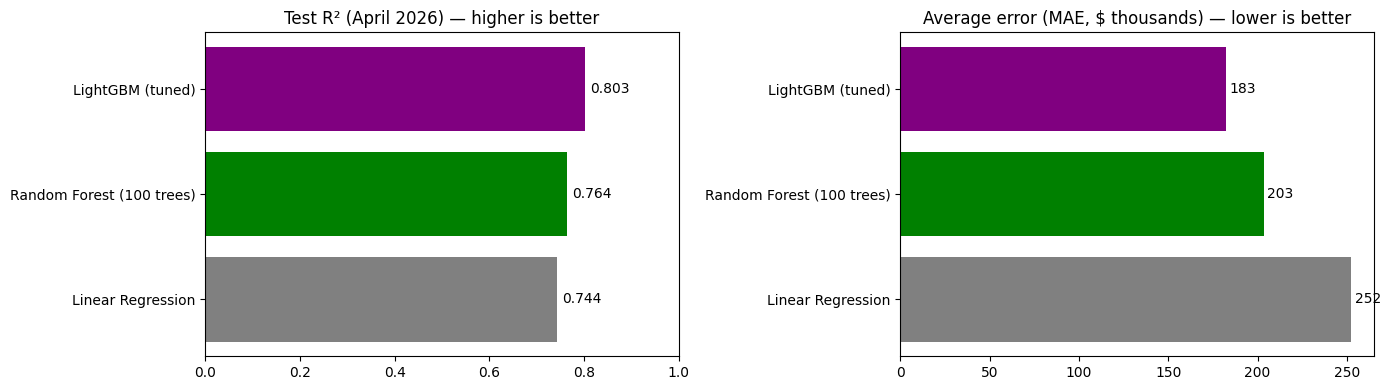

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = ["gray", "green", "purple"]

axes[0].barh(results_df.index, results_df["test R2"], color=colors)
axes[0].set_title("Test R² (April 2026) — higher is better")
axes[0].set_xlim(0, 1)
for i, v in enumerate(results_df["test R2"]):
    axes[0].text(v + 0.01, i, round(v, 3), va="center")

axes[1].barh(results_df.index, results_df["MAE ($)"] / 1000, color=colors)
axes[1].set_title("Average error (MAE, $ thousands) — lower is better")
for i, v in enumerate(results_df["MAE ($)"] / 1000):
    axes[1].text(v + 2, i, round(v), va="center")

plt.tight_layout()
plt.show()

**What I notice:**
- **LightGBM is the best model so far: test R² = 0.8047**, up from 0.7620 for the Random Forest and 0.7398 for Linear Regression (same features for all three).
- The average error (MAE) drops to about **\$189,000**, compared with about \$203,000 for the Random Forest.
- The typical percent miss (MdAPE) is about **8.3%**, similar to the Random Forest (8.2%). LightGBM mostly wins on the expensive homes, where dollar errors are big.
- It also trains in about **18 seconds**, about half the Random Forest's time.
- Gradient boosting wins because each new tree focuses on the homes the earlier trees got wrong, instead of averaging independent trees.

## 8. How good are LightGBM's predictions?

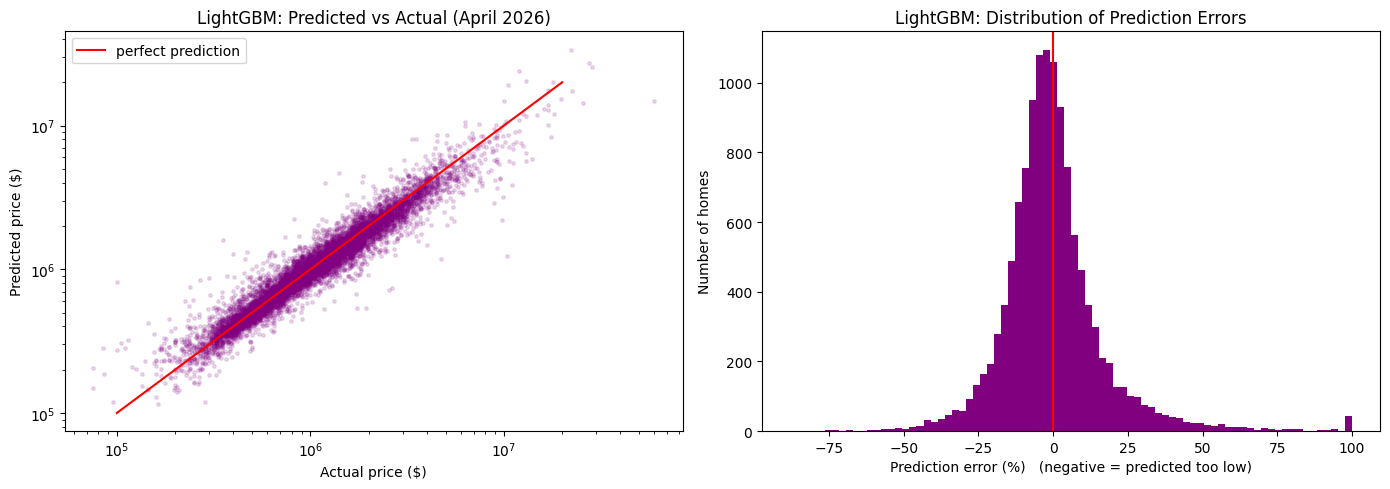

Homes predicted within 10% of the actual price: 59.2 %
Homes predicted within 20% of the actual price: 84.3 %


In [15]:
pred_price = np.exp(gbm_pred)
pct_error = (pred_price - actual_price) / actual_price * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(actual_price, pred_price, alpha=0.15, s=6, color="purple")
axes[0].plot([1e5, 2e7], [1e5, 2e7], color="red", label="perfect prediction")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("LightGBM: Predicted vs Actual (April 2026)")
axes[0].legend()

axes[1].hist(pct_error.clip(-100, 100), bins=80, color="purple")
axes[1].axvline(0, color="red")
axes[1].set_xlabel("Prediction error (%)   (negative = predicted too low)")
axes[1].set_ylabel("Number of homes")
axes[1].set_title("LightGBM: Distribution of Prediction Errors")
plt.tight_layout()
plt.show()

print("Homes predicted within 10% of the actual price:", round((abs(pct_error) <= 10).mean() * 100, 1), "%")
print("Homes predicted within 20% of the actual price:", round((abs(pct_error) <= 20).mean() * 100, 1), "%")

**What I notice:**
- Most points sit close to the red line, so predictions are usually close to the real price.
- About **57%** of April homes are predicted within **10%** of their real price, and about **83%** within **20%**.
- The error histogram is centered at 0, so the model doesn't consistently guess too high or too low.
- The biggest misses are still the very cheap and very expensive homes at the edges of the plot.

## 9. Which features does LightGBM use most?
LightGBM's **gain** importance shows how much each feature reduced the error in total, across all trees.

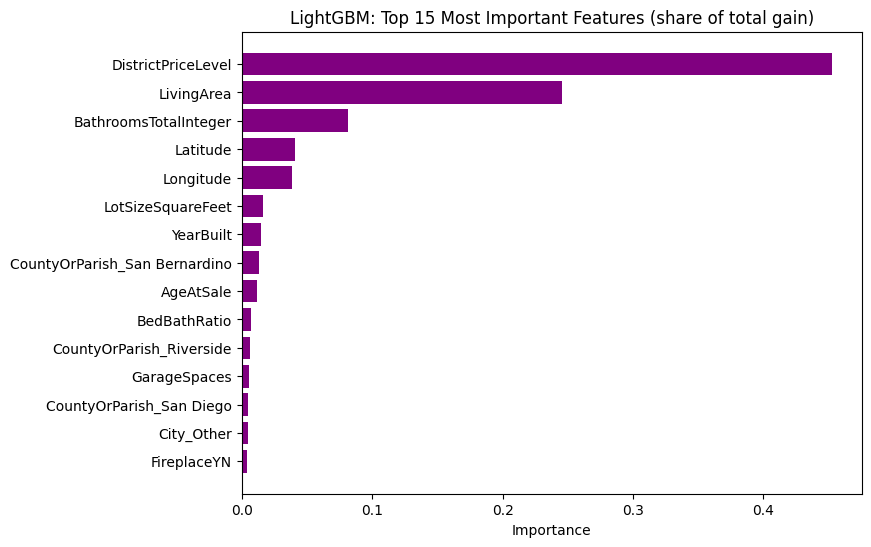

In [16]:
importance = pd.Series(gbm.booster_.feature_importance(importance_type="gain"), index=X_train.columns)
importance = (importance / importance.sum()).sort_values(ascending=False)
top15 = importance.head(15)

plt.figure(figsize=(8, 6))
plt.barh(top15.index[::-1], top15.values[::-1], color="purple")
plt.title("LightGBM: Top 15 Most Important Features (share of total gain)")
plt.xlabel("Importance")
plt.show()

**What I notice:**
- **DistrictPriceLevel** (the Week 6 school district feature) is by far the most important, at almost **half** of the total gain.
- **LivingArea** is second (~25%), then the number of bathrooms.
- Latitude and longitude still help a little, along with lot size and age.
- So **location + size** explain most of a home's price, which matches everything I found in earlier weeks.

## 10. What if I drop the extreme prices?
So far I kept **every** April home in the score. A few very cheap homes and $10M+ mansions cause huge dollar errors, and they pull R² down a lot.

Here I try three versions of the same tuned LightGBM (same settings as section 6):
1. **Keep all homes** (what I did above)
2. **Drop the top and bottom 0.5% of prices** from both train and test
3. **Drop the bottom 5% and top 0.5% of prices** from both train and test

The price cutoffs come from the **training data only**, so the test month doesn't influence them. After dropping homes, I recalculate the district price level and run `prepare()` again, so everything is learned from the kept training homes only.

I also add **MdAPE** (median absolute percentage error). It's the "typical" percent miss: half of the homes are predicted closer than this.

*This cell takes about a minute.*

In [17]:
low_05 = train["ClosePrice"].quantile(0.005)
low_5 = train["ClosePrice"].quantile(0.05)
high_995 = train["ClosePrice"].quantile(0.995)
print(f"Bottom 0.5% cutoff: ${low_05:,.0f}")
print(f"Bottom 5% cutoff:   ${low_5:,.0f}")
print(f"Top 0.5% cutoff:    ${high_995:,.0f}")

versions = [
    ("1. Keep all homes", 0, np.inf),
    ("2. Drop top/bottom 0.5%", low_05, high_995),
    ("3. Drop bottom 5% + top 0.5%", low_5, high_995),
]

trim_results = []
for name, low_cut, high_cut in versions:
    tr = train[(train["ClosePrice"] >= low_cut) & (train["ClosePrice"] <= high_cut)]
    te = test[(test["ClosePrice"] >= low_cut) & (test["ClosePrice"] <= high_cut)]
    tr_lvl, te_lvl = add_district_level(tr, te)
    Xtr, Xte, ytr, yte = prepare(tr_lvl, te_lvl, extra_cols=new_cols)

    model = lgb.LGBMRegressor(n_estimators=best_trees, learning_rate=best_lr, max_depth=best_depth,
                              num_leaves=2 ** best_depth - 1, min_child_samples=20,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              random_state=42, verbose=-1)
    model.fit(Xtr, ytr)
    pred = np.exp(model.predict(Xte))
    actual = np.exp(yte)

    trim_results.append({
        "version": name,
        "price range kept": "all" if high_cut == np.inf else f"${low_cut:,.0f} to ${high_cut:,.0f}",
        "train rows": len(tr),
        "test rows": len(te),
        "test homes dropped": len(test) - len(te),
        "test R2": r2_score(actual, pred),
        "test R2 (log)": r2_score(yte, np.log(pred)),
        "MAE ($)": mean_absolute_error(actual, pred),
        "MdAPE (%)": np.median(np.abs(pred - actual) / actual) * 100,
    })
    print(name, "-> test R²:", round(trim_results[-1]["test R2"], 4))

Bottom 0.5% cutoff: $195,000
Bottom 5% cutoff:   $369,000
Top 0.5% cutoff:    $8,300,450
1. Keep all homes -> test R²: 0.8028
2. Drop top/bottom 0.5% -> test R²: 0.8975
3. Drop bottom 5% + top 0.5% -> test R²: 0.8938


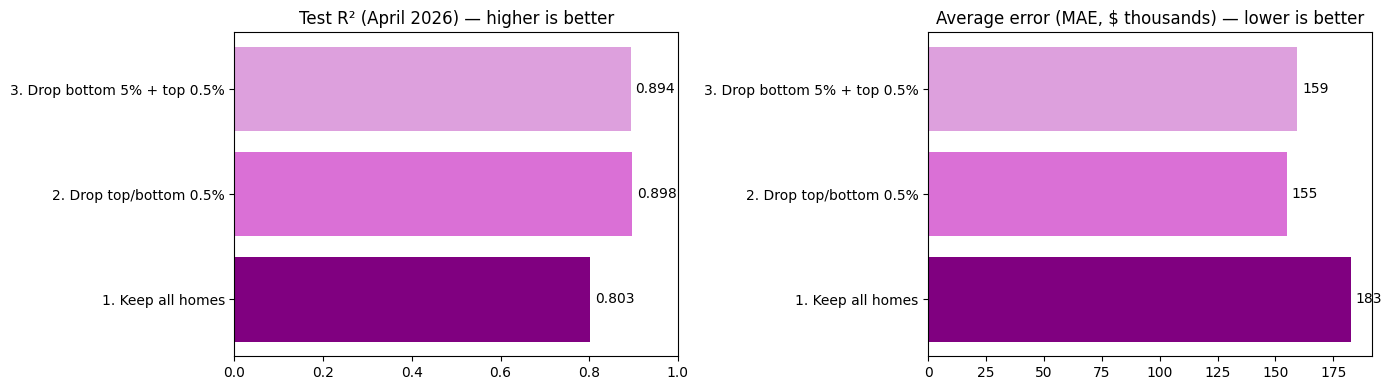

In [18]:
trim_df = pd.DataFrame(trim_results).set_index("version")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(trim_df.index, trim_df["test R2"], color=["purple", "orchid", "plum"])
axes[0].set_title("Test R² (April 2026) — higher is better")
axes[0].set_xlim(0, 1)
for i, v in enumerate(trim_df["test R2"]):
    axes[0].text(v + 0.01, i, round(v, 3), va="center")

axes[1].barh(trim_df.index, trim_df["MAE ($)"] / 1000, color=["purple", "orchid", "plum"])
axes[1].set_title("Average error (MAE, $ thousands) — lower is better")
for i, v in enumerate(trim_df["MAE ($)"] / 1000):
    axes[1].text(v + 2, i, round(v), va="center")
plt.tight_layout()
plt.show()

**What I notice:**
- Dropping only **127 of 12,465** April homes (about 1%, the ones under \$195K or over \$8.3M) raises test R² from **0.805 to 0.889**.
- The MAE drops from about **\$189K to \$162K**.
- So most of the "missing" R² came from a handful of extreme homes. A single \$20M home that's off by 30% adds as much squared error as hundreds of normal homes.
- The typical percent miss (MdAPE) barely changes (**8.3% → 8.1%**), so the model is just as good on normal homes either way.
- Also dropping the **bottom 5%** (under \$369K, 702 test homes) **doesn't help**: R² is 0.887, about the same. The cheap homes weren't the problem; the very expensive ones were.

## 11. Final table: all the versions side by side

In [19]:
final_table = pd.concat([
    results_df.loc[["Linear Regression", "Random Forest (100 trees)"]].assign(**{"price range kept": "all", "test homes dropped": 0}),
    trim_df.rename(index=lambda v: "LightGBM — " + v[3:]),
])
final_table = final_table[["price range kept", "test R2", "test R2 (log)", "MAE ($)", "MdAPE (%)", "test homes dropped"]]
final_table

,price range kept,test R2,test R2 (log),MAE ($),MdAPE (%),test homes dropped
Linear Regression,all,0.7437,0.8782,"252,323.8611",11.6078,0
Random Forest (100 trees),all,0.7644,0.9169,"203,461.8530",8.2960,0
LightGBM — Keep all homes,all,0.8028,0.9342,"182,516.4328",7.8315,0
LightGBM — Drop top/bottom 0.5%,"$195,000 to $8,300,450",0.8975,0.9365,"154,994.1985",7.7715,127
LightGBM — Drop bottom 5% + top 0.5%,"$369,000 to $8,300,450",0.8938,0.9335,"159,450.8027",7.5127,702


**What I notice:**
- **LightGBM beats Linear Regression and Random Forest** on every metric when all homes are kept (R² 0.805 vs 0.762 and 0.740).
- **Dropping the top/bottom 0.5% of prices** gives my best score: **R² = 0.889, MAE ≈ \$162K, MdAPE ≈ 8.1%**.
- Dropping more homes (bottom 5%) doesn't improve things, so **version 2 is the one I'd use**.
- When I report a score, I need to say which version it is, e.g. *"R² = 0.889 on April 2026, excluding homes under \$195K or over \$8.3M (about 1% of sales)."*

## 12. Save the results

In [ ]:
final_table.to_csv(os.path.join(path, "advanced_model_results.csv"))
tuning.to_csv(os.path.join(path, "lightgbm_tuning.csv"), index=False)
print("Saved advanced_model_results.csv and lightgbm_tuning.csv")

Saved advanced_model_results.csv and lightgbm_tuning.csv


: 

## Summary (Week 7)
- I tried **Gradient Boosting** with **LightGBM** on the Week 6 feature set.
- **Light tuning on March 2026** (never on the test month) over `max_depth` (4, 6, 8) × `learning_rate` (0.05, 0.1), with `n_estimators` picked from the validation error curve.
- **Best settings:** max_depth = 4, learning_rate = 0.05, n_estimators = 4,996.
- I also tested **dropping extreme prices** (cutoffs from the training data).

| Model | Homes kept | Test R² | MAE | MdAPE |
|---|---|---|---|---|
| Linear Regression | all | 0.740 | ~\$252K | 11.6% |
| Random Forest | all | 0.762 | ~\$203K | 8.2% |
| LightGBM (tuned) | all | 0.805 | ~\$189K | 8.3% |
| **LightGBM (tuned)** | **\$195K – \$8.3M (drop top/bottom 0.5%)** | **0.889** | **~\$162K** | **8.1%** |
| LightGBM (tuned) | \$369K – \$8.3M (drop bottom 5% + top 0.5%) | 0.887 | ~\$166K | 7.9% |

- **LightGBM is my best model**, and it trains faster than the Random Forest.
- Dropping the top/bottom 0.5% of prices raises R² a lot (0.805 → 0.889), because the few \$10M+ homes cause most of the big dollar errors.
- **Next step (Week 8):** look closer at where the model makes its biggest errors (by county, price range, and home type).